# 03 — Scenario engineering

## What are we trying to solve?

Features such as distance, speed, direction, pressure, and visibility are not possession labels. They become useful when combined into a football situation that explains what may happen next. This notebook keeps that reasoning under a small set of cases instead of presenting a gallery of repeated plots.

A scenario is evidence context. It can delay a decision, lower confidence, or open a transition interval; it does not create `H` or `A` by itself.

## Case dictionary

| Case | Observable evidence | Football interpretation | Downstream use |
|---|---|---|---|
| Missing ball | endpoint continuity, direction, player arrival, pressure | the ball may be hidden, travelling, or out of play | compare path hypotheses; preserve uncertainty when receivers remain ambiguous |
| Short touch / handoff | proximity change, contact-like speed change, forward persistence | a touch may or may not change ownership | open a local H↔A hypothesis; require control before switching |
| Long ball | coherent flight, displacement, landing-area density, receiver path | launch team has continuity during flight, but landing ownership is unresolved | hold the prior state until landing/control evidence |
| Contested | both teams arrive or converge without stable control | neither team can yet own the ball confidently | retain `CONTESTED`/`NO_SWITCH` evidence |
| Restart | tag context, near-stationary phase, activation, first controlled touch | dead ball is ending but play is not necessarily live at the first appearance | keep `D` until activation plus control evidence |

In [1]:
# Build the canonical evidence table once. Public labels are audit-only.
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
while not (ROOT / 'possession_lab').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from possession_lab.baseline_pipeline import ClosestTeamRuleModel, slot_team_map
from possession_lab.calculations.features import build_engineered_features
from possession_lab.calculations.plotting import plot_timeline_window, select_evidence_window
from possession_lab.calculations.scenario_evidence import build_scenario_evidence
from possession_lab.temporal_rules import load_rules
from games import asset_paths

rules = load_rules()
model = ClosestTeamRuleModel()
features = build_engineered_features(model=model, rules=rules)
team_by_slot = slot_team_map(asset_paths(model.game, model.data_dir, source='tactical')['atd_meta'])
gt_path = ROOT / 'evaluation' / 'gt' / 'BAR-ATH_possession_gt_public.csv'
gt_by_frame = pd.read_csv(gt_path).set_index('frame')['label'] if gt_path.exists() else None
insight_path = ROOT / 'data' / 'first_half_gt.csv'
insight_gt_by_frame = pd.read_csv(insight_path).set_index('frame')['label'] if insight_path.exists() else gt_by_frame

case_windows = {
    'case_a_missing_ball': select_evidence_window(features, kind='missing_ball', context_frames=50),
    'case_b_candidate_transition': select_evidence_window(features, kind='transition', context_frames=75),
}
print('feature table:', features.shape)
print(features['scenario_context'].value_counts(dropna=False).to_string())

feature table: (199319, 662)
scenario_context
OCCLUDED                 71724
BALL_IN_FLIGHT           27831
RESTART_LIVE_BOUNDARY    22378
DEAD                     17558
UNKNOWN                  16051
CONTROLLED               15781
CONTESTED                10455
PRESSURED_CONTROL        10188
RECEPTION_CANDIDATE       5812
TRANSITION_CANDIDATE      1539
RECEPTION                    2


## Case A — missing ball

A missing coordinate is not a switch. We compare the last and next reliable observations, then ask whether a straight path, a player-supported deflection, or a dead/resting explanation fits the surrounding movement. A path hypothesis is passed downstream as evidence; it is not a filled ownership label.

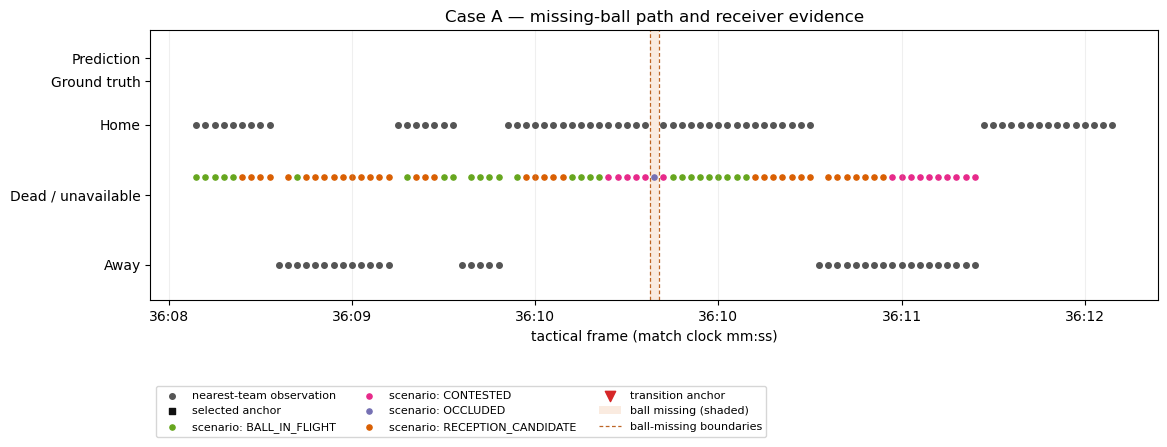

In [2]:
window = case_windows['case_a_missing_ball']
if window is None:
    print('No missing-ball case found.')
else:
    fig, ax = plot_timeline_window(features, *window, ground_truth=gt_by_frame)
    ax.set_title('Case A — missing-ball path and receiver evidence')
    plt.show()

## Case B — short touch or candidate handoff

The nearest player can change during a pass, deflection, or poor touch. We therefore combine proximity with a contact-like ball change, candidate arrival, pressure, and short forward persistence. This opens a local transition hypothesis; it does not globally rewrite `CONTESTED` into `H` or `A`.

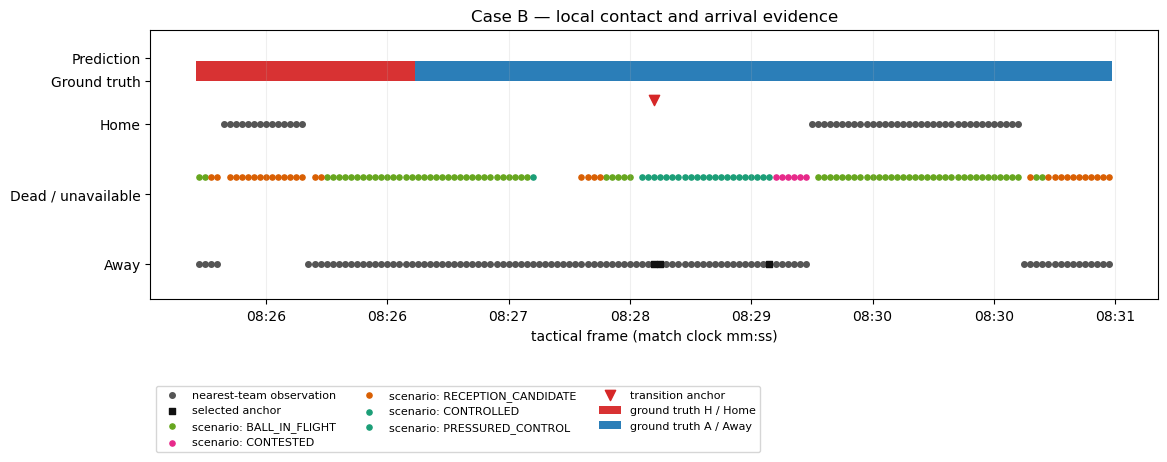

In [3]:
window = case_windows['case_b_candidate_transition']
if window is None:
    print('No candidate transition case found.')
else:
    fig, ax = plot_timeline_window(features, *window, ground_truth=gt_by_frame)
    ax.set_title('Case B — local contact and arrival evidence')
    plt.show()

## Case C — observed turnover

A public H/A change is used only to audit the evidence around an event. Looking backward shows the previous control and approach; looking forward shows whether the candidate receiver actually controls the ball. This is why transition decisions are interval-based rather than nearest-player decisions.

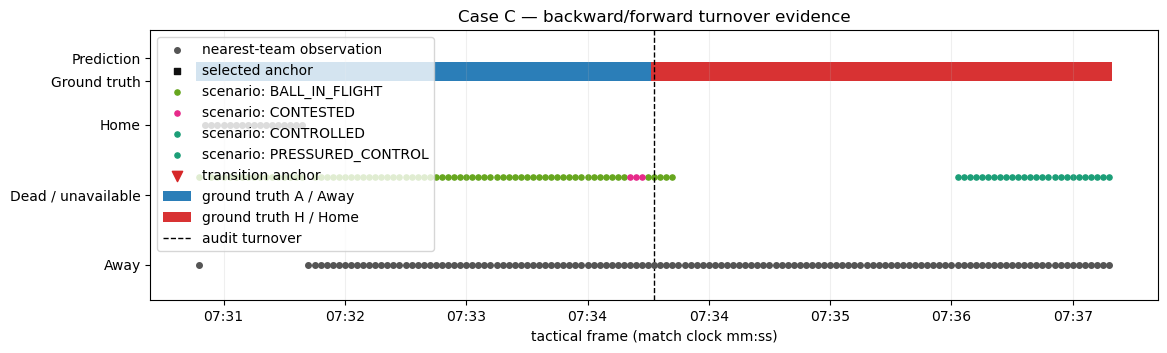

In [4]:
gt_known = gt_by_frame.dropna() if gt_by_frame is not None else pd.Series(dtype=object)
gt_h_a = gt_known[gt_known.isin(['H', 'A'])]
gt_switches = gt_h_a.index[(gt_h_a != gt_h_a.shift()) & gt_h_a.shift().isin(['H', 'A'])]
if len(gt_switches) == 0:
    print('No public H/A turnover available.')
else:
    frame = int(gt_switches[0])
    left = max(int(features['frame'].min()), frame - 75)
    right = min(int(features['frame'].max()), frame + 75)
    fig, ax = plot_timeline_window(features, left, right, ground_truth=gt_by_frame)
    ax.axvline(frame, color='black', linestyle='--', linewidth=1, label='audit turnover')
    ax.set_title('Case C — backward/forward turnover evidence')
    ax.legend(loc='upper left')
    plt.show()

## Case D — long-ball outcomes

A launch supports continuity for the launching team during flight, but it does not prove who wins the landing. We compare a turnover outcome with a same-team continuation, using the public/hand-annotated labels only to select retrospective examples.

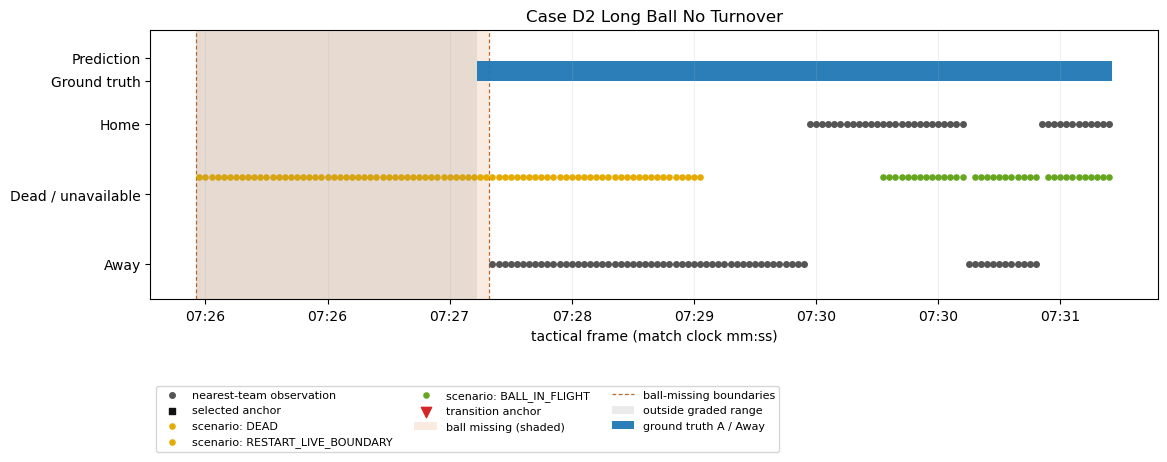

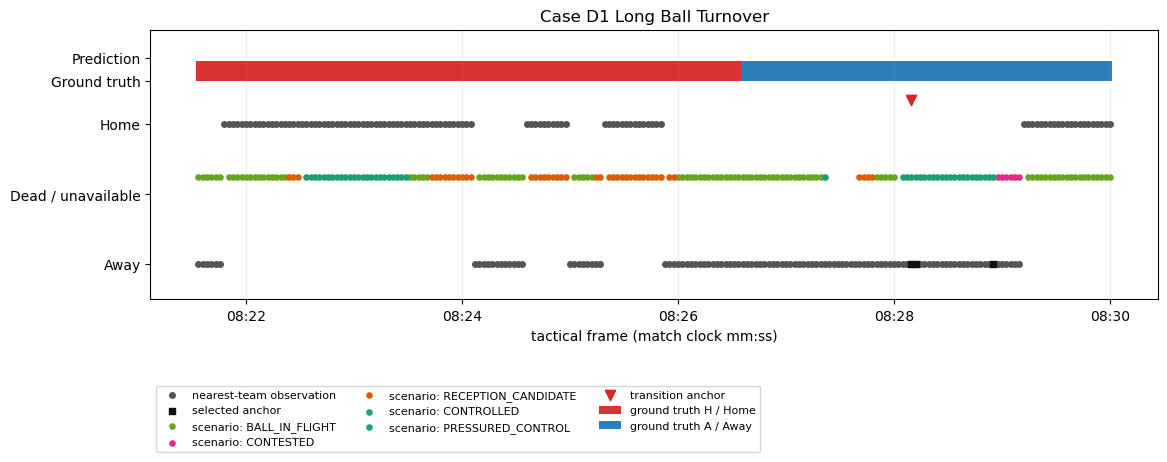

retrospective long-ball cases: {'case_d2_long_ball_no_turnover': (11139, 11288), 'case_d1_long_ball_turnover': (12539, 12750)}


In [5]:
audit_gt = insight_gt_by_frame.dropna() if insight_gt_by_frame is not None else pd.Series(dtype=object)
long_signal = features.get('long_ball_evidence', pd.Series(False, index=features.index)).fillna(False).to_numpy(bool)
starts = np.flatnonzero(long_signal & ~np.r_[False, long_signal[:-1]])
ends = np.flatnonzero(long_signal & ~np.r_[long_signal[1:], False])
long_cases = {}
for start, end in zip(starts, ends):
    flight_start = int(features.iloc[start]['frame'])
    flight_end = int(features.iloc[end]['frame'])
    before = audit_gt.loc[audit_gt.index < flight_start]
    after = audit_gt.loc[audit_gt.index > flight_end]
    if before.empty or after.empty:
        continue
    prior, later = before.iloc[-1], after.iloc[0]
    if prior not in ['H', 'A'] or later not in ['H', 'A']:
        continue
    key = 'case_d1_long_ball_turnover' if prior != later else 'case_d2_long_ball_no_turnover'
    if key not in long_cases:
        long_cases[key] = (max(int(features['frame'].min()), flight_start - 50), min(int(features['frame'].max()), flight_end + 75))

for key, (left, right) in long_cases.items():
    fig, ax = plot_timeline_window(features, left, right, ground_truth=insight_gt_by_frame)
    ax.set_title(key.replace('_', ' ').title())
    plt.show()
print('retrospective long-ball cases:', long_cases)

## Case evidence passed to the pipeline

The compact record keeps significant player paths, arrival/pressure summaries, and frame-level scenario context. The transition layer then tests `KEEP_CURRENT`, `SWITCH_TO_H`, `SWITCH_TO_A`, `ENTER_D`, restart hypotheses, and `CONTESTED`. The interval resolver decides when evidence is strong enough to change the final label.

In [6]:
scenario_evidence = {}
for name, bounds in {**case_windows, **long_cases}.items():
    if bounds is None:
        continue
    evidence = build_scenario_evidence(features, *bounds, team_by_slot, radius_m=12.0)
    scenario_evidence[name] = {
        'summary': evidence['summary'],
        'players': evidence['summary_table'].to_dict('records'),
        'frames': evidence['trajectory_table'].replace({np.nan: None}).to_dict('records'),
    }
trajectory_path = ROOT / 'cache' / 'scenario_case_player_trajectories.json'
trajectory_path.parent.mkdir(parents=True, exist_ok=True)
trajectory_path.write_text(json.dumps(scenario_evidence, indent=2, default=str), encoding='utf-8')
print(f'saved case evidence: {trajectory_path}')

saved case evidence: /Users/luke/Desktop/barca-hack-repo-staging/cache/scenario_case_player_trajectories.json


## Findings

- Closest-player evidence proposes a receiver; it does not prove control.
- Missing-ball and long-ball intervals need path agreement plus player arrival and post-touch persistence.
- A contested episode should remain unresolved rather than being forced into a team label.
- Restart context protects `D`, while physical activation and control evidence determine when live play resumes.
- These cases motivate the conservative hypothesis-test resolver used by the full-match pipeline.